# 1. Diagnosis: what is driving the open tickets?

Leadership says open tickets are up about 60% since July and wants the number down. Three people on the
team each blame something different. Before picking a side, I wanted to see what the 1,444 tickets say.

The notebook follows the questions in the order I asked them. The numbers that matter are repeated in
the write-up.

## Setting up

I read the ticket file and add a few columns that the rest of the notebook keeps using: whether a
ticket was escalated, whether it is still open, whether engineering sent it back without a fix (I call
that "bounced"), and how long it took.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../backend/data/rideops_support_tickets.csv")

for col in ["created_at", "first_response_at", "first_closed_at", "final_closed_at"]:
    df[col] = pd.to_datetime(df[col])

# The data was pulled at the end of 30 Sep 2026. We treat that as "now".
now = pd.Timestamp("2026-09-30 23:59")

df["escalated"] = df["escalated_to_eng"] == "Yes"
df["is_open"] = df["status"] != "Closed"
df["reopened"] = df["reopen_count"] > 0

# "Bounced" = sent to engineering, but engineering did not fix it
df["eng_outcome"] = df["eng_outcome"].fillna("")
df["bounced"] = df["escalated"] & (df["eng_outcome"] != "Fixed")

df["hours_to_close"] = (df["final_closed_at"] - df["created_at"]).dt.total_seconds() / 3600

end_time = df["final_closed_at"].fillna(now)
df["age_hours"] = (end_time - df["created_at"]).dt.total_seconds() / 3600

# Replace numbers with N, so similar problems get the same name
df["issue_type"] = df["description"].str.replace(r"\d+", "N", regex=True)

print("Tickets:", len(df))

Tickets: 1444


In [2]:
df[["ticket_id", "created_at", "category", "assigned_agent", "escalated",
    "eng_handoffs", "eng_outcome", "status", "hours_to_close"]].head()

,ticket_id,created_at,category,assigned_agent,escalated,eng_handoffs,eng_outcome,status,hours_to_close
0,SUP-10001,2026-07-02 01:27:00,Live tracking / GPS incorrect,Priya D,False,0,,Closed,5.583333
1,SUP-10002,2026-07-02 02:53:00,Login / access issue,Vikram S,False,0,,Closed,6.250000
2,SUP-10003,2026-07-02 04:38:00,Live tracking / GPS incorrect,Arjun K,False,0,,Closed,14.466667
3,SUP-10004,2026-07-02 05:15:00,Live tracking / GPS incorrect,Arjun K,True,1,Fixed,Closed,65.466667
4,SUP-10005,2026-07-02 08:25:00,Login / access issue,Arjun K,False,0,,Closed,1.966667


## Is the backlog really growing?

First, how many tickets came in each month.

In [3]:
df["month"] = df["created_at"].dt.strftime("%Y-%m")
tickets_per_month = df.groupby("month").size()
print(tickets_per_month)

growth = tickets_per_month["2026-09"] / tickets_per_month["2026-07"] - 1
print("Growth from July to September:", round(growth * 100), "%")

month
2026-07    390
2026-08    462
2026-09    592
dtype: int64
Growth from July to September: 52 %


Volume is clearly up. Now the backlog itself: how many tickets were open at the end of each week.

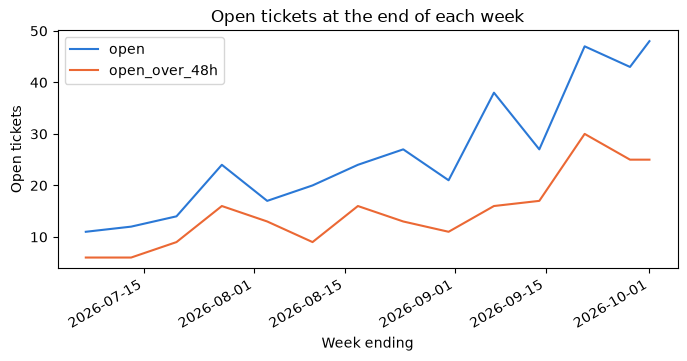

,week_end,open,open_over_48h
0,2026-07-06 00:00:00,11,6
1,2026-07-13 00:00:00,12,6
2,2026-07-20 00:00:00,14,9
3,2026-07-27 00:00:00,24,16
4,2026-08-03 00:00:00,17,13
5,2026-08-10 00:00:00,20,9
6,2026-08-17 00:00:00,24,16
7,2026-08-24 00:00:00,27,13
8,2026-08-31 00:00:00,21,11
9,2026-09-07 00:00:00,38,16


In [4]:
# For each Monday, count the tickets that were open at that moment
week_ends = list(pd.date_range("2026-07-06", "2026-09-28", freq="7D")) + [now]

rows = []
for day in week_ends:
    created_before = df["created_at"] < day
    not_closed_yet = df["final_closed_at"].isna() | (df["final_closed_at"] >= day)
    open_then = df[created_before & not_closed_yet]

    hours_open = (day - open_then["created_at"]).dt.total_seconds() / 3600
    older_than_48h = open_then[hours_open >= 48]

    rows.append({"week_end": day, "open": len(open_then), "open_over_48h": len(older_than_48h)})

backlog = pd.DataFrame(rows)

backlog.plot(x="week_end", y=["open", "open_over_48h"], color=["#2a78d6", "#eb6834"],
             title="Open tickets at the end of each week", figsize=(8, 3.5))
plt.xlabel("Week ending")
plt.ylabel("Open tickets")
plt.show()
backlog

The weekly line is jumpy, so a single week can mislead. Leadership quoted "about 60% since July", so I
checked that figure directly, with a count for every day.

In [5]:
# Count the open tickets at the end of every day
days = pd.date_range("2026-07-03", "2026-09-30", freq="D") + pd.Timedelta(hours=23, minutes=59)

rows = []
for day in days:
    created_before = df["created_at"] < day
    not_closed_yet = df["final_closed_at"].isna() | (df["final_closed_at"] >= day)
    open_then = df[created_before & not_closed_yet]
    hours_open = (day - open_then["created_at"]).dt.total_seconds() / 3600
    rows.append({"day": day, "open": len(open_then), "open_over_48h": (hours_open >= 48).sum()})

daily = pd.DataFrame(rows)
daily["month"] = daily["day"].dt.strftime("%Y-%m")

# Open tickets on the last day of July and the last day of September
end_of_july = daily[daily["day"].dt.strftime("%m-%d") == "07-31"]["open"].iloc[0]
end_of_september = daily[daily["day"].dt.strftime("%m-%d") == "09-30"]["open"].iloc[0]
print("Open at the end of July:", end_of_july)
print("Open at the end of September:", end_of_september)
print("Growth:", round((end_of_september / end_of_july - 1) * 100), "%")
print()

# Average number of open tickets on a normal day, for each month
print(daily.groupby("month")[["open", "open_over_48h"]].mean().round(1))

Open at the end of July: 30
Open at the end of September: 48
Growth: 60 %

         open  open_over_48h
month                       
2026-07  21.3            7.2
2026-08  29.2           13.0
2026-09  42.9           20.2


The 60% figure holds up: 30 tickets were open at the end of July and 48 at the end of September. The
count swings from day to day, though, so two single days are a thin basis. The monthly averages above
are steadier, but July needs care.

In [6]:
# The file starts on 2 July with nothing open, because older tickets are not in it.
# So early July looks quieter than it really was. Compare the second half of each month.
late_july = daily[(daily["day"] >= "2026-07-17") & (daily["day"] < "2026-08-01")]["open"].mean()
late_september = daily[daily["day"] >= "2026-09-15"]["open"].mean()
print("Average open per day, 17 to 31 July:", round(late_july, 1))
print("Average open per day, 15 to 30 September:", round(late_september, 1))

Average open per day, 17 to 31 July: 26.5
Average open per day, 15 to 30 September: 49.2


Comparing like with like, about 27 tickets were open on a typical day in late July and about 49 in late
September. The whole-month averages (21 and 43) overstate the growth, because the file begins with an
empty backlog.

Tickets open for more than 48 hours grew faster than the total, from about 7 a day in July to about 20
in September.

## What changed between July and September?

Before looking for a cause, it helps to put the three months side by side: how much work arrived, how
often it was escalated and returned, and how long each stage took.

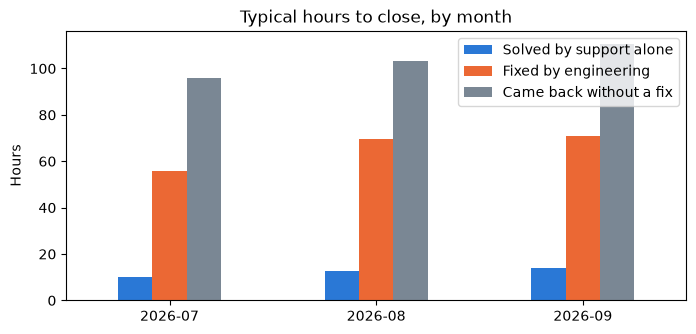

month,2026-07,2026-08,2026-09
new_tickets,390.0,462.0,592.0
escalated_pct,37.4,32.7,31.9
first_response_hours,2.0,2.5,3.2
avg_hours_open,41.3,46.0,50.1
came_back_pct,54.1,56.3,58.7
came_back_count,79.0,85.0,111.0
hours_support_alone,10.1,12.6,13.8
hours_engineering_fix,55.6,69.5,71.0
hours_came_back,95.9,103.1,110.7


In [7]:
df["first_response_hours"] = (df["first_response_at"] - df["created_at"]).dt.total_seconds() / 3600
sent = df[df["escalated"]]

by_month = df.groupby("month").agg(
    new_tickets=("ticket_id", "count"),
    escalated_pct=("escalated", "mean"),
    first_response_hours=("first_response_hours", "median"),
    avg_hours_open=("age_hours", "mean"),
)
by_month["escalated_pct"] = by_month["escalated_pct"] * 100
by_month["came_back_pct"] = sent.groupby("month")["bounced"].mean() * 100
by_month["came_back_count"] = sent.groupby("month")["bounced"].sum()
by_month["hours_support_alone"] = df[~df["escalated"]].groupby("month")["hours_to_close"].median()
by_month["hours_engineering_fix"] = df[df["eng_outcome"] == "Fixed"].groupby("month")["hours_to_close"].median()
by_month["hours_came_back"] = df[df["bounced"]].groupby("month")["hours_to_close"].median()

by_month[["hours_support_alone", "hours_engineering_fix", "hours_came_back"]].plot(
    kind="bar", color=["#2a78d6", "#eb6834", "#7a8794"], figsize=(8, 3.5),
    title="Typical hours to close, by month")
plt.xlabel("")
plt.ylabel("Hours")
plt.xticks(rotation=0)
plt.legend(["Solved by support alone", "Fixed by engineering", "Came back without a fix"])
plt.show()
by_month.round(1).T

In [8]:
# A rough check: tickets arriving per day x days a ticket stays open = tickets open at once
days_in_month = pd.Series({"2026-07": 30, "2026-08": 31, "2026-09": 30})
expected_open = by_month["new_tickets"] / days_in_month * by_month["avg_hours_open"] / 24
print("Expected open tickets from volume and time open:")
print(expected_open.round(0))
print()
print("Measured average open tickets per day:")
print(daily.groupby("month")["open"].mean().round(0))

Expected open tickets from volume and time open:
month
2026-07    22.0
2026-08    29.0
2026-09    41.0
dtype: float64

Measured average open tickets per day:
month
2026-07    21.0
2026-08    29.0
2026-09    43.0
Name: open, dtype: float64


Two things moved, and one did not.

Volume rose 52%. And every stage got slower: support's own tickets went from about 10 hours to 14, an
engineering fix from about 56 to 71, and first response from 2.0 hours to 3.2. The average ticket now
stays open about a fifth longer, 50 hours against 41.

The share of escalations that come back barely moved. It was 54% in July and 59% in September, and the
share of tickets being escalated actually fell. So the returns were there from the start. They did not
cause the rise.

The rough check agrees. Tickets arriving per day, times how long a ticket stays open, gives 22, 29 and
41 open tickets for the three months. The measured averages are 21, 29 and 43. More work, handled more
slowly, accounts for the bigger pile.

September's times are, if anything, understated, because tickets still open on 30 September are only
counted up to that day.

This changes the question for the rest of the notebook. The team cannot control how many tickets arrive
this quarter. So where is time being spent that it could get back?

## Where does the waiting time go?

Two groups: tickets that support solved alone, and tickets that went to engineering.

In [9]:
compare = df.groupby("escalated").agg(
    tickets=("ticket_id", "count"),
    typical_hours=("hours_to_close", "median"),
    average_rating=("csat_score", "mean"),
    total_waiting_hours=("age_hours", "sum"),
)

compare["share_of_tickets_%"] = compare["tickets"] / compare["tickets"].sum() * 100
compare["share_of_waiting_%"] = compare["total_waiting_hours"] / compare["total_waiting_hours"].sum() * 100
compare.index = ["Solved by support alone", "Sent to engineering"]
compare.round(1)

,tickets,typical_hours,average_rating,total_waiting_hours,share_of_tickets_%,share_of_waiting_%
Solved by support alone,958,12.6,4.0,19147.9,66.3,28.6
Sent to engineering,486,86.8,3.1,47855.5,33.7,71.4


Escalated tickets are a third of the volume (34%) but hold 71% of all the waiting time. They take about
87 hours to close, against about 13 for the rest, and clients rate them lower (3.1 against 4.0).

So Meera has a point: the slow tickets are the ones that go to engineering. The next question is why
they are slow.

## What happens to a ticket once engineering has it?

`eng_outcome` is engineering's final answer on each escalated ticket.

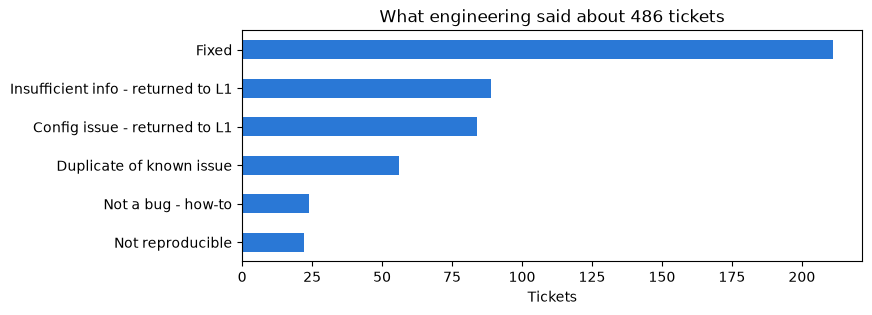

,tickets,typical_hours,average_rating
eng_outcome,,,
Fixed,211,64.8,3.4
Insufficient info - returned to L1,89,121.1,2.7
Config issue - returned to L1,84,128.6,2.4
Duplicate of known issue,56,67.5,3.5
Not a bug - how-to,24,68.7,3.2
Not reproducible,22,62.3,3.4


In [10]:
sent_to_eng = df[df["escalated"]]

outcomes = sent_to_eng.groupby("eng_outcome").agg(
    tickets=("ticket_id", "count"),
    typical_hours=("hours_to_close", "median"),
    average_rating=("csat_score", "mean"),
)
outcomes = outcomes.sort_values("tickets", ascending=False)

outcomes["tickets"].sort_values().plot(kind="barh", color="#2a78d6", figsize=(8, 3),
                                       title="What engineering said about 486 tickets")
plt.ylabel("")
plt.xlabel("Tickets")
plt.show()
outcomes.round(1)

In [11]:
fixed = sent_to_eng[sent_to_eng["eng_outcome"] == "Fixed"]
bounced = sent_to_eng[sent_to_eng["bounced"]]

print("Sent to engineering:", len(sent_to_eng))
print("Really fixed by engineering:", len(fixed))
print("Came back without a fix:", len(bounced))
print("Came back, as % of sent:", round(len(bounced) / len(sent_to_eng) * 100), "%")
print("Came back, as % of ALL tickets:", round(len(bounced) / len(df) * 100), "%")
print("Came back, as % of ALL waiting time:", round(bounced["age_hours"].sum() / df["age_hours"].sum() * 100), "%")

Sent to engineering: 486
Really fixed by engineering: 211
Came back without a fix: 275
Came back, as % of sent: 57 %
Came back, as % of ALL tickets: 19 %
Came back, as % of ALL waiting time: 47 %


Engineering fixed 211 of the 486 tickets it received. The other 275 (57%) came back with one of five
answers:

- not enough information (89)
- a settings problem that support could have fixed (84)
- already known to engineering (56)
- a how-to question, not a bug (24)
- could not reproduce it (22)

Those 275 are 19% of all tickets and 47% of all waiting time. That supports Sandeep.

It does not clear engineering, though. The "Fixed" row shows that even a real fix takes about 65 hours.

## What does a second or third trip cost?

`eng_handoffs` counts how many times a ticket went to engineering.

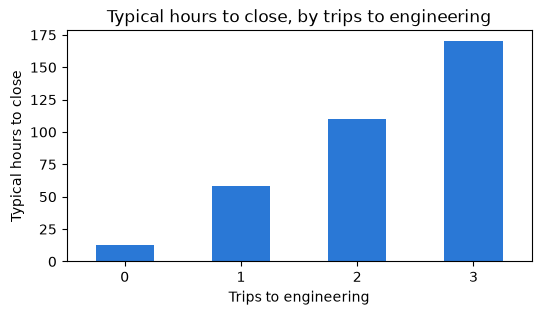

Tickets with 2 or more trips: 229


,tickets,typical_hours,average_rating
eng_handoffs,,,
0,958,12.6,4.0
1,257,58.6,3.6
2,167,110.4,2.8
3,62,169.9,2.1


In [12]:
trips = df.groupby("eng_handoffs").agg(
    tickets=("ticket_id", "count"),
    typical_hours=("hours_to_close", "median"),
    average_rating=("csat_score", "mean"),
)

trips["typical_hours"].plot(kind="bar", color="#2a78d6", figsize=(6, 3),
                            title="Typical hours to close, by trips to engineering")
plt.xlabel("Trips to engineering")
plt.ylabel("Typical hours to close")
plt.xticks(rotation=0)
plt.show()

print("Tickets with 2 or more trips:", (df["eng_handoffs"] >= 2).sum())
trips.round(1)

Which tickets are the ones making two or three trips? Below is engineering's answer against the number
of trips.

In [13]:
# Rows: what engineering said. Columns: how many trips the ticket made.
pd.crosstab(sent_to_eng["eng_outcome"], sent_to_eng["eng_handoffs"])

eng_handoffs,1,2,3
eng_outcome,,,
Config issue - returned to L1,0,51,33
Duplicate of known issue,44,12,0
Fixed,173,38,0
Insufficient info - returned to L1,0,60,29
Not a bug - how-to,20,4,0
Not reproducible,20,2,0


In [14]:
total_trips = sent_to_eng["eng_handoffs"].sum()
trips_not_fixed = sent_to_eng[sent_to_eng["bounced"]]["eng_handoffs"].sum()
print("Trips to engineering in three months:", total_trips)
print("Trips spent on tickets engineering did not fix:", trips_not_fixed)
print("As a share of all trips:", round(trips_not_fixed / total_trips * 100), "%")

Trips to engineering in three months: 777
Trips spent on tickets engineering did not fix: 528
As a share of all trips: 68 %


The time grows with every trip: about 59 hours for one, 110 for two and 170 for three. The rating falls
with it, from 3.6 to 2.8 to 2.1. In all, 229 tickets made two or more trips.

The cross-table shows who they are. Tickets returned for missing information or for a settings problem
never made just one trip. Together they account for 173 of the 229. Real fixes mostly needed one.

Counted as trips, the picture is sharper. Engineering received 777 trips in three months, and 528 of
them (68%) were for tickets it did not end up fixing. That is engineering time that could be going to
real fixes, and it is the time this team can get back without hiring.

A caution: this shows that more trips go with longer times. It does not prove that removing a trip
saves exactly that many hours.

## Is it one kind of problem?

In [15]:
by_category = df.groupby("category").agg(
    tickets=("ticket_id", "count"),
    sent_to_eng_rate=("escalated", "mean"),
    typical_hours=("hours_to_close", "median"),
)
# Of the tickets sent to engineering, what share came back?
by_category["sent_to_eng"] = sent_to_eng.groupby("category").size()
by_category["came_back_rate"] = sent_to_eng.groupby("category")["bounced"].mean()

by_category.sort_values("tickets", ascending=False).round(2)

,tickets,sent_to_eng_rate,typical_hours,sent_to_eng,came_back_rate
category,,,,,
Roster / booking not syncing,344,0.51,44.48,175,0.55
Live tracking / GPS incorrect,228,0.56,42.73,127,0.53
Report export failing,206,0.37,23.87,77,0.66
Cab delay / no-show complaint,147,0.10,10.75,14,0.36
How-to / feature request,104,0.12,8.98,12,0.75
Login / access issue,100,0.08,7.62,8,0.62
OTP / boarding issue,95,0.36,18.50,34,0.62
Billing / invoice discrepancy,88,0.30,39.62,26,0.50
Employee address / geocode change,75,0.15,17.93,11,0.55


Roster and GPS tickets are the two largest groups. Between them they are 40% of all tickets, and more
than half of each goes to engineering.

But the return rate is not special to them. It sits between 50% and 66% in all five categories that
escalate the most. The smaller categories sent 14 tickets or fewer, which is too few to read anything
into.

So this is not one broken category. It looks like a problem with how tickets are handed over.

## Is it particular agents?

In [16]:
by_agent = df.groupby("assigned_agent").agg(
    tickets=("ticket_id", "count"),
    sent_to_eng_rate=("escalated", "mean"),
    typical_hours=("hours_to_close", "median"),
    reopened_rate=("reopened", "mean"),
    average_rating=("csat_score", "mean"),
)
by_agent["came_back_rate"] = sent_to_eng.groupby("assigned_agent")["bounced"].mean()

by_agent.round(2)

,tickets,sent_to_eng_rate,typical_hours,reopened_rate,average_rating,came_back_rate
assigned_agent,,,,,,
Ananya R,189,0.40,24.06,0.07,3.84,0.47
Arjun K,178,0.33,20.78,0.08,3.85,0.57
Karan B,217,0.16,11.88,0.29,3.13,0.63
Neha P,171,0.29,19.73,0.08,3.94,0.61
Priya D,186,0.33,22.38,0.09,3.78,0.54
Rahul T,151,0.62,44.48,0.08,3.52,0.75
Sneha M,176,0.35,25.78,0.05,3.72,0.49
Vikram S,176,0.30,20.83,0.05,3.92,0.40


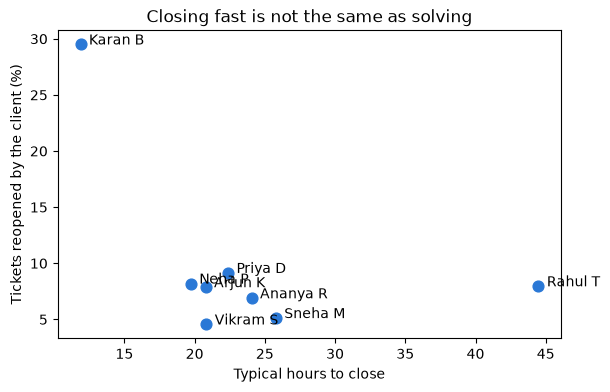

In [17]:
# Fast closing compared with how often the client reopens the ticket
plt.figure(figsize=(6.5, 4))
plt.scatter(by_agent["typical_hours"], by_agent["reopened_rate"] * 100, color="#2a78d6", s=60)
for name in by_agent.index:
    plt.text(by_agent.loc[name, "typical_hours"] + 0.6, by_agent.loc[name, "reopened_rate"] * 100, name)
plt.xlabel("Typical hours to close")
plt.ylabel("Tickets reopened by the client (%)")
plt.title("Closing fast is not the same as solving")
plt.show()

Two agents stand out in that table and in the chart. Before reading too much into it, I checked whether
some agents simply get harder tickets: first the mix of categories each one handles, then how they
behave inside a single category.

In [18]:
# Share of each agent's tickets that fall in the three biggest categories (%)
mix = pd.crosstab(df["assigned_agent"], df["category"], normalize="index") * 100
big_three = ["Roster / booking not syncing", "Live tracking / GPS incorrect", "Report export failing"]
print(mix[big_three].round(0))
print()

# Inside the same category, how often does each agent send the ticket to engineering?
roster = df[df["category"] == "Roster / booking not syncing"]
print(roster.groupby("assigned_agent")["escalated"].agg(["count", "mean"]).round(2))

category        Roster / booking not syncing  Live tracking / GPS incorrect  \
assigned_agent                                                                
Ananya R                                24.0                           18.0   
Arjun K                                 22.0                           16.0   
Karan B                                 26.0                           15.0   
Neha P                                  21.0                           15.0   
Priya D                                 25.0                           13.0   
Rahul T                                 21.0                           20.0   
Sneha M                                 25.0                           14.0   
Vikram S                                26.0                           16.0   

category        Report export failing  
assigned_agent                         
Ananya R                         11.0  
Arjun K                          14.0  
Karan B                          13.0  
Neha P   

The mix is nearly identical for all eight agents, so it does not explain the gap. Within roster tickets
alone, Rahul T escalated every one of his 32. Most of the others escalated about half, and Karan B a
fifth.

Overall, Rahul T escalates 62% of his tickets (the rest range from 16% to 40%), and 75% of those come
back.

Karan B is the opposite case. He closes fastest, in about 12 hours, and escalates least. But clients
reopen about 30% of his tickets, against 5% to 9% for everyone else, and his rating is the lowest on the
team. His tickets are being closed before the problem is solved.

This matters for Meera's argument that fast agents show it can be done quickly. The fastest agent is
fast because the work comes back. A "close faster" target would reward exactly that.

## What does not explain it

Client size, channel and priority, for completeness.

In [19]:
for col in ["client_tier", "channel", "priority"]:
    table = df.groupby(col).agg(tickets=("ticket_id", "count"), sent_to_eng_rate=("escalated", "mean"))
    print(table.round(2))
    print()

             tickets  sent_to_eng_rate
client_tier                           
Enterprise       614              0.34
Mid-market       656              0.34
SMB              174              0.33

               tickets  sent_to_eng_rate
channel                                 
Client portal      377              0.34
Email              553              0.34
Phone              292              0.33
WhatsApp           222              0.32

          tickets  sent_to_eng_rate
priority                           
P1             67              0.33
P2            264              0.35
P3            742              0.33
P4            371              0.34



Nothing here. About a third of tickets are escalated in every group.

## Where is the extra volume coming from?

Volume is the largest single driver, so it is worth knowing which tickets grew.

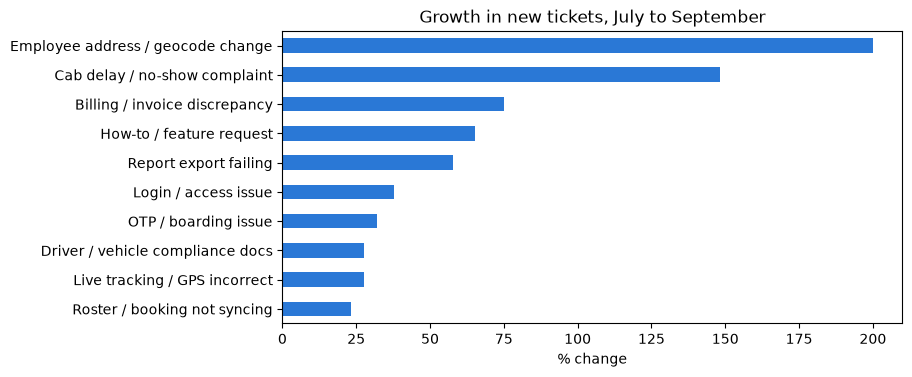

month,2026-07,2026-08,2026-09,change_pct,escalated_pct
category,,,,,
Employee address / geocode change,13,23,39,200.0,15.0
Cab delay / no-show complaint,29,46,72,148.0,10.0
Billing / invoice discrepancy,24,22,42,75.0,30.0
How-to / feature request,23,43,38,65.0,12.0
Report export failing,57,59,90,58.0,37.0
Login / access issue,29,31,40,38.0,8.0
OTP / boarding issue,28,30,37,32.0,36.0
Driver / vehicle compliance docs,18,16,23,28.0,4.0
Live tracking / GPS incorrect,65,80,83,28.0,56.0


In [20]:
volume = pd.crosstab(df["category"], df["month"])
volume["change_pct"] = (volume["2026-09"] / volume["2026-07"] - 1) * 100
volume["escalated_pct"] = df.groupby("category")["escalated"].mean() * 100
volume = volume.sort_values("change_pct")

volume["change_pct"].plot(kind="barh", color="#2a78d6", figsize=(8, 3.8),
                          title="Growth in new tickets, July to September")
plt.xlabel("% change")
plt.ylabel("")
plt.show()
volume.sort_values("change_pct", ascending=False).round(0)

In [21]:
# Is the growth from new clients, or from existing clients raising more tickets?
first_month = df.groupby("client_name")["month"].min()
df["client_since"] = df["client_name"].map(first_month)

july = df[df["month"] == "2026-07"]
september = df[df["month"] == "2026-09"]
print("July tickets:", len(july))
print("September tickets from clients already active in July:", (september["client_since"] == "2026-07").sum())
print("September tickets from clients first seen later:", (september["client_since"] != "2026-07").sum())

July tickets: 390
September tickets from clients already active in July: 524
September tickets from clients first seen later: 68


The fastest growth is in address changes (up 200%) and cab delay complaints (up 148%). Those rarely
reach engineering: 15% and 10% of them are escalated. Roster and GPS tickets, which escalate most, grew
the least (23% and 28%).

It is also mostly existing clients raising more tickets. Clients already active in July raised 390
tickets that month and 524 in September. Clients first seen later added 68.

So the volume growth is largely an operations problem (cabs arriving late, addresses changing). A
better handover to engineering will not reduce it. It needs its own work, and it is in the plan.

## Where this leaves the three views

| Claim | Holds up? | Why |
|---|---|---|
| Open tickets are up about 60% | Yes | 30 open at the end of July, 48 at the end of September |
| Engineering is slow (Meera) | Partly | Escalated tickets are 71% of waiting time, and a fix went from 56 to 71 hours |
| Support sends the wrong tickets (Sandeep) | Yes | 57% of escalated tickets come back, in every month |
| Fast agents show it can be done fast (Meera) | No | The fastest agent has the most reopened tickets |

Open tickets rose because 52% more tickets arrived and every stage slowed by about a fifth under that
load. The returns did not cause the rise: they were as high in July.

They are still where I would start, because they are the time the team can recover. 68% of
engineering's trips go to tickets it does not fix. Removing those gives engineering time back for real
fixes, and it needs no new staff.